# Лабораторная работа 1 — рабочий ноутбук

**ФИО: Рудьман Иван Олегович.**

**Файлы данных:**

1. data/clients.csv;
2. data/transactions.csv.


## 0. Окружение и настройки

In [124]:
import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS_PATH = "../../data/clients.csv"
RAW_TXN_PATH = "../../data/transactions.csv"

PERIOD_START = pd.Timestamp("2024-01-01")
PERIOD_END = pd.Timestamp("2025-06-30")

# буфер журнала изменений: одно решение — одна запись
log_rows = []

## 1. Загрузка сырых данных


### 1.1. Загрузка clients.csv


Наивно прочитаем файл с клиентами

In [125]:
df_clients = pd.read_csv(RAW_CLIENTS_PATH)
print('Размер таблицы:', df_clients.shape)
print('Типы столбцов:', df_clients.dtypes, sep = '\n')
df_clients.head(5)

Размер таблицы: (5719, 16)
Типы столбцов:
client_id                 str
birth_date                str
gender                    str
city                      str
segment                   str
loyalty_tier              str
card_type                 str
registration_date         str
card_open_date            str
income_source             str
monthly_income        float64
has_mobile_app            str
app_last_login            str
satisfaction_score    float64
branch_code             int64
marketing_opt_in          str
dtype: object


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C002786,1960-11-04,Ж,Казань,Массовый,Базовый,Дебетовая,02.03.2021,22.06.2023,Зарплата в другом банке,52500.0,Нет,NaN,5.0,905,Да
1,C003601,1988-05-11,Ж,Казань,Массовый,Базовый,Дебетовая,09.12.2022,21.02.2025,Зарплата в нашем банке,57600.0,Нет,NaN,NaN,635,Нет
2,C003692,1976-10-16,Ж,СПб,Премиальный,Серебро,Дебетовая,18.09.2014,25.04.2018,Зарплата в нашем банке,105300.0,Да,2025-03,NaN,872,Да
3,C005100,1983-02-13,Ж,Н. Новгород,Зарплатный,Базовый,Кредитная,26.10.2019,18.03.2025,Зарплата в нашем банке,94800.0,Да,2025-03,NaN,443,Да
4,C001633,1976-05-24,М,Нижний Новгород,Массовый,Базовый,Дебетовая,20.04.2018,14.09.2021,Зарплата в другом банке,47700.0,Да,2025-03,2.0,598,Да


Файл прочитался хорошо, но видим, что категориальные типы не определились, а даты прочитались как строки. Исправим это в следующем блоке на основе данных вывода и Task.md.

In [126]:
df_clients = pd.read_csv(
    RAW_CLIENTS_PATH,
    dtype={
        'client_id': 'string',
        # категориальные признаки
        'gender': 'category',
        'city': 'category',
        'segment': 'category',
        'loyalty_tier': 'category',
        'card_type': 'category',
        'income_source': 'category',
        'has_mobile_app': 'category',
        'marketing_opt_in': 'category',
        # числовые признаки
        'monthly_income': 'float64',
        'satisfaction_score': 'Int64',   # 1..5, есть пропуски -> nullable int
        'branch_code': 'int64',
        # даты читаем как строки и парсим отдельно (форматы разные)
        'birth_date': 'string',
        'registration_date': 'string',
        'card_open_date': 'string',
        'app_last_login': 'string',
    },
)

df_clients['birth_date']        = pd.to_datetime(df_clients['birth_date'],        format='%Y-%m-%d')
df_clients['registration_date'] = pd.to_datetime(df_clients['registration_date'], format='%d.%m.%Y')
df_clients['card_open_date']    = pd.to_datetime(df_clients['card_open_date'],    format='%d.%m.%Y')
df_clients['app_last_login']    = pd.to_datetime(df_clients['app_last_login'],    format='%Y-%m', errors='coerce')

print('Типы столбцов:', df_clients.dtypes, sep = '\n')

Типы столбцов:
client_id                     string
birth_date            datetime64[us]
gender                      category
city                        category
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source               category
monthly_income               float64
has_mobile_app              category
app_last_login        datetime64[us]
satisfaction_score             Int64
branch_code                    int64
marketing_opt_in            category
dtype: object


## 1.2 transactions.csv

Попробуем прочитать наивно:


In [127]:
try:
    df_transactions = pd.read_csv(RAW_TXN_PATH)
except Exception as e:
    print('Ошибка при чтении файла:', e)

Ошибка при чтении файла: 'utf-8' codec can't decode byte 0xce in position 7: invalid continuation byte


Предположим, что кодировка файла cp1251, т.к. данные на кириллице:


In [128]:
df_transactions = pd.read_csv(RAW_TXN_PATH, encoding = 'cp1251')
print('Размер таблицы:', df_transactions.shape)
print('Типы столбцов:', df_transactions.dtypes, sep = '\n')
df_transactions.head(5)

Размер таблицы: (625276, 1)
Типы столбцов:
txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status    str
dtype: object


,txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status
990163;C001976;2023-12-10;4638,38;RUB;Одежда и обувь;5651;Карта;успешно
990199;C004215;2023-12-12 12:19:56;507,22;RUB;Продукты;5411;Карта;успешно
990072;C004029;2023-12-17 13:59:08;902,94;RUB;Продукты;5411;Карта;успешно
990033;C001144;2023-12-17 14:36:01;247,73;RUB;Продукты;5411;Карта;успешно
990046;C001369;2023-12-28 06:54:01;135,79;RUB;Транспорт;4111;Карта;успешно


Данные слиплись, т.к. сепаратором в данных является символ `;`. Исправим это в следующем блоке. И сразу укажем нужные типы данных на основе того, что увидели.

In [129]:
df_transactions = pd.read_csv(
    RAW_TXN_PATH,
    dtype={
        'txn_id': 'Int64',
        'client_id': 'string',
        'txn_datetime': 'string',
        'amount': 'string',
        'currency': 'category',
        'category': 'category',
        'mcc_code': 'Int64',
        'channel': 'category',
        'status': 'category',
    },
     encoding='cp1251', sep=';'
)

df_transactions['txn_datetime']    = pd.to_datetime(df_transactions['txn_datetime'], errors='coerce', format='mixed')
df_transactions['amount'] = df_transactions['amount'].str.replace(",", ".").astype('float64')


print('Размер таблицы:', df_transactions.shape)
df_transactions.head(5)

Размер таблицы: (625276, 9)


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990163,C001976,2023-12-10 00:00:00,4638.38,RUB,Одежда и обувь,5651,Карта,успешно
1,990199,C004215,2023-12-12 12:19:56,507.22,RUB,Продукты,5411,Карта,успешно
2,990072,C004029,2023-12-17 13:59:08,902.94,RUB,Продукты,5411,Карта,успешно
3,990033,C001144,2023-12-17 14:36:01,247.73,RUB,Продукты,5411,Карта,успешно
4,990046,C001369,2023-12-28 06:54:01,135.79,RUB,Транспорт,4111,Карта,успешно


### 1.3. Итог загрузки

Файлы выгружены из разных систем, и это видно по трём признакам сразу:

| файл | кодировка | разделитель | десятичный разделитель | формат дат |
|---|---|---|---|---|
| `clients.csv` | UTF-8 | `,` | точка | `%d.%m.%Y` и `%Y-%m-%d` |
| `transactions.csv` | cp1251 | `;` | запятая | `%Y-%m-%d %H:%M:%S` |

Чтение «по умолчанию» дало ошибку кодировки у операций и один столбец вместо девяти. Поэтому параметры чтения заданы явно, а типы объявлены на входе: даты и числа разбираются один раз, при загрузке, а не заново в каждом блоке.

Результат: **5719 строк клиентов** и **625276 строк операций**.


## 2. Аудит качества

### 2.1. Объём, типы, ключи, единица наблюдения

In [130]:
# --- объём, ключи, единица наблюдения
print("clients.csv")
print(df_clients.dtypes.to_string())
print("\ntransactions.csv")
print(df_transactions.dtypes.to_string())

print("\nпериод операций в файле:", df_transactions["txn_datetime"].min().date(), "—", df_transactions["txn_datetime"].max().date())
print("заявленный период:", PERIOD_START.date(), "—", PERIOD_END.date())

missing = pd.DataFrame({"пропусков": df_clients.isna().sum(), "доля, %": (df_clients.isna().mean() * 100).round(1)})
print("\nпропуски в clients.csv (знаменатель —", len(df_clients), "строк):")
print(missing[missing["пропусков"] > 0].to_string())
print("\nсуммарно пропусков в transactions.csv:", int(df_transactions.isna().sum().sum()))

keys = pd.DataFrame(
    {
        "строк": [len(df_clients), len(df_transactions)],
        "уникальных ключей": [df_clients["client_id"].nunique(), df_transactions["txn_id"].nunique()],
        "единица наблюдения": ["клиент", "операция"],
    },
    index=["clients.csv", "transactions.csv"],
)
keys["строк сверх ключа"] = keys["строк"] - keys["уникальных ключей"]
keys


clients.csv
client_id                     string
birth_date            datetime64[us]
gender                      category
city                        category
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source               category
monthly_income               float64
has_mobile_app              category
app_last_login        datetime64[us]
satisfaction_score             Int64
branch_code                    int64
marketing_opt_in            category

transactions.csv
txn_id                   Int64
client_id               string
txn_datetime    datetime64[us]
amount                 float64
currency              category
category              category
mcc_code                 Int64
channel               category
status                category

период операций в файле: 2023-12-10 — 2026-08-01
заявленный период: 2024-01-01 — 2025-06-30

пропу

,строк,уникальных ключей,единица наблюдения,строк сверх ключа
clients.csv,5719,5664,клиент,55
transactions.csv,625276,623776,операция,1500


**Что видно.** Обе таблицы читаются, типы объяснимы, но в каждой есть «строки сверх ключа»: 55 у клиентов и 1500 у операций. Значит, прежде чем считать любую долю, нужно разобраться с дублями — иначе знаменатель завышен.

Пропуски есть только в справочнике: `monthly_income` 9.2%, `app_last_login` 38.8%, `satisfaction_score` 60.7% (знаменатель — 5719 строк файла). В операциях пропусков нет ни в одном поле.

Период в файле шире заявленного: 2023-12-10 … 2026-08-01 против 2024-01-01 … 2025-06-30.

Единица наблюдения разная: клиент в первой таблице и операция во второй. Поэтому «сколько клиентов» и «сколько операций» — разные знаменатели, и смешивать их в одной доле нельзя.


### 2.2. Дубли

In [131]:
# --- клиенты: полные дубли и дубли по ключу
clients_exact = df_clients.drop_duplicates()
conflict = clients_exact["client_id"].duplicated(keep=False)

print("clients.csv, строк:", len(df_clients))
print("  полных дублей строк:", len(df_clients) - len(clients_exact))
print(
    "  client_id с противоречивыми атрибутами:",
    int(conflict.sum()),
    "строк /",
    int(clients_exact.loc[conflict, "client_id"].nunique()),
    "идентификаторов",
)

clients_exact.loc[conflict].sort_values("client_id")[
    ["client_id", "birth_date", "city", "segment", "loyalty_tier", "monthly_income"]
].head(10)


clients.csv, строк: 5719
  полных дублей строк: 40
  client_id с противоречивыми атрибутами: 30 строк / 15 идентификаторов


,client_id,birth_date,city,segment,loyalty_tier,monthly_income
335,C000317,1974-12-31,г. Санкт-Петербург,Зарплатный,Базовый,103200.0
5152,C000317,1974-12-31,Екатеринбург,Private,Базовый,103200.0
4859,C000490,1982-09-01,Н. Новгород,Массовый,Серебро,58200.0
2993,C000490,1982-09-01,Нижний Новгород,Премиальный,Серебро,58200.0
2174,C000501,1968-11-03,Екатеринбург,Массовый,Базовый,116200.0
1435,C000501,1968-11-03,Казань,Массовый,Базовый,116200.0
2943,C000608,1989-09-05,г. Новосибирск,Премиальный,Серебро,159200.0
2873,C000608,1989-09-05,Казань,Private,Серебро,159200.0
3823,C001338,1951-05-30,Нижний Новгород,Зарплатный,Серебро,67700.0
5332,C001338,1951-05-30,Новосибирск,Премиальный,Серебро,67700.0


In [132]:
# --- операции: полные дубли и дубли по ключу
txn_exact = df_transactions.drop_duplicates()
midnight = txn_exact["txn_datetime"].dt.time.eq(datetime.time(0, 0))
same_id = txn_exact.duplicated(subset=["txn_id"], keep=False)

print("transactions.csv, строк:", len(df_transactions))
print("  полных дублей строк:", len(df_transactions) - len(txn_exact))
print("  операций с потерянным временем (00:00:00 при наличии пары с точным временем):", int((midnight & same_id).sum()))
print("  записей 00:00:00 без пары по txn_id:", int((midnight & ~same_id).sum()))

txn_exact.loc[same_id].sort_values("txn_id")[
    ["txn_id", "client_id", "txn_datetime", "amount", "category"]
].head(10)


transactions.csv, строк: 625276
  полных дублей строк: 1281
  операций с потерянным временем (00:00:00 при наличии пары с точным временем): 219
  записей 00:00:00 без пары по txn_id: 49683


,txn_id,client_id,txn_datetime,amount,category
1037,101028,C005442,2024-01-02 13:26:45,1945.08,Продукты
1038,101028,C005442,2024-01-02 00:00:00,1945.08,Продукты
2297,102286,C003905,2024-01-04 12:17:50,76.51,Транспорт
2298,102286,C003905,2024-01-04 00:00:00,76.51,Транспорт
8470,108436,C005176,2024-01-10 13:38:46,423.02,Онлайн-сервисы
8471,108436,C005176,2024-01-10 00:00:00,423.02,Онлайн-сервисы
13451,113409,C000019,2024-01-16 00:00:00,1264.30,Развлечения и досуг
13452,113409,C000019,2024-01-16 17:20:35,1264.30,Развлечения и досуг
15301,115256,C001976,2024-01-19 00:00:00,4638.38,Одежда и обувь
15302,115256,C001976,2024-01-19 13:57:00,4638.38,Одежда и обувь


**Что видно.** У клиентов 40 полных дублей и 15 идентификаторов, у которых расходятся город и сегмент. Второе — не дубль, а два разных описания одного человека, и по данным нельзя выбрать верное.

У операций 1281 полный дубль и отдельная проблема: у 219 операций одна запись хранит `00:00:00`, а вторая — точное время при том же `txn_id`. При этом ещё 49 683 записи имеют `00:00:00` и пары не имеют: время теряется не только у дублей, а примерно у 8% операций. Для разреза по месяцам это не критично (дата сохранена), для «в какое время суток платят» такие записи непригодны.


### 2.3. Соответствие данных описанию полей из задания

In [133]:
print("city:", df_clients["city"].nunique(), "значений на", len(df_clients), "клиентов")
print(df_clients["city"].value_counts().to_string())

print("\ncategory:", df_transactions["category"].nunique(), "значений")
print(df_transactions["category"].value_counts().to_string())

mcc_mode = df_transactions.groupby("category", observed=True)["mcc_code"].agg(lambda s: s.mode().iloc[0])
off_mcc = df_transactions["mcc_code"].ne(df_transactions["category"].map(mcc_mode))
print("\nmcc_code не совпадает с ведущим кодом своей категории:", int(off_mcc.sum()), f"({off_mcc.mean():.2%})")
print(mcc_mode.to_string())


city: 17 значений на 5719 клиентов
city
Москва                1094
Казань                 712
Санкт-Петербург        665
Нижний Новгород        543
Новосибирск            541
Екатеринбург           488
казань                 213
 москва                211
МОСКВА                 201
г. Новосибирск         167
Н. Новгород            161
г. Москва              160
Санкт Петербург        122
ЕКАТЕРИНБУРГ           118
СПб                    115
г. Санкт-Петербург     109
г.Екатеринбург          99

category: 12 значений
category
Продукты               164490
Транспорт               71439
Одежда и обувь          64991
АЗС                     58008
Кафе и рестораны        48814
Развлечения и досуг     47712
Аптеки                  45046
Онлайн-сервисы          43616
Связь и интернет        29341
Связь и Интернет        19226
кафе и рестораны        16446
Кафе/рестораны          16147

mcc_code не совпадает с ведущим кодом своей категории: 1707 (0.27%)
category
АЗС                    5541
Апт

In [134]:
print("валюты:", df_transactions["currency"].value_counts().to_dict())
print("статусы:", df_transactions["status"].value_counts().to_dict())

negative = df_transactions["amount"].lt(0)
returns = df_transactions["status"].eq("возврат")
print("\nотрицательных сумм:", int(negative.sum()))
print("знак совпадает со статусом «возврат»:", bool(negative.eq(returns).all()))

out_of_period = ~df_transactions["txn_datetime"].dt.normalize().between(PERIOD_START, PERIOD_END)
print("\nопераций вне заявленного периода:", int(out_of_period.sum()))
print(df_transactions.loc[out_of_period, "txn_datetime"].dt.to_period("M").value_counts().sort_index().to_string())

income = df_clients["monthly_income"]
print("\nрежимы записи дохода:")
print("  пусто:", int(income.isna().sum()))
print("  заглушка -999:", int(income.lt(0).sum()))
print("  записано в тысячах (0 < x < 1000):", int((income.gt(0) & income.lt(1000)).sum()))
print("  в рублях (>= 1000):", int(income.ge(1000).sum()))

print("\napp_last_login пуст ровно у клиентов без приложения:", bool(df_clients["app_last_login"].isna().eq(df_clients["has_mobile_app"].eq("Нет")).all()))
print("branch_code:", df_clients["branch_code"].nunique(), "значений,", round(df_clients.groupby("branch_code", observed=True)["city"].nunique().mean(), 1), "города на отделение в среднем")


валюты: {'RUB': 622653, 'EUR': 1315, 'USD': 1308}
статусы: {'успешно': 605455, 'отклонено': 12273, 'возврат': 7548}

отрицательных сумм: 7548
знак совпадает со статусом «возврат»: True

операций вне заявленного периода: 85
txn_datetime
2023-12     6
2025-07     5
2025-08     5
2025-09    11
2025-10     4
2025-11     7
2025-12     5
2026-01     6
2026-02     7
2026-03     6
2026-04     7
2026-05     5
2026-06     7
2026-07     3
2026-08     1
Freq: M

режимы записи дохода:
  пусто: 525
  заглушка -999: 47
  записано в тысячах (0 < x < 1000): 174
  в рублях (>= 1000): 4973

app_last_login пуст ровно у клиентов без приложения: True
branch_code: 840 значений, 5.0 города на отделение в среднем


**Расхождения с описанием полей.**

1. `city` — 17 написаний на 6 реальных городов (регистр, приставка «г.», дефис или пробел).
2. `category` — 12 значений вместо девяти: «Кафе/рестораны», «кафе и рестораны», «Связь и Интернет».
3. `mcc_code` — описан как «соответствует категории», но 1707 строк (0.27%) несут код чужой категории. Соответствие почти строгое, но не полное.
4. `status` — три значения, и отрицательные суммы есть ровно у возвратов (7548 из 7548): знак суммы не независим от статуса и сам по себе типом операции не является.
5. `txn_datetime` — 85 операций вне заявленного периода: 6 в декабре 2023 и 79 в июле 2025 — августе 2026.
6. `monthly_income` — три режима записи в одном поле: пропуск (525), заглушка −999 (47) и запись в тысячах (174).
7. `app_last_login` — пропуск строго совпадает с «приложение не установлено», то есть структурный, а не потерянный.
8. `branch_code` — 840 значений при 5649 клиентах и в среднем 5 городов на отделение: код не описывает ни клиента, ни географию.

Пункты 1 и 2 — дефекты записи, их видно по самим значениям. Пункт 8 — расхождение описания с фактом: файл не испорчен, но описание поля ему не соответствует, и это надо зафиксировать, а не «починить» данные под описание.


### 2.4. Связь между таблицами

In [135]:
in_reference = df_transactions["client_id"].isin(df_clients["client_id"])
without_ops = ~df_clients["client_id"].isin(df_transactions["client_id"])

print("уникальных client_id в операциях:", df_transactions["client_id"].nunique())
print("из них нет в справочнике:", df_transactions.loc[~in_reference, "client_id"].nunique())
print("строк операций без клиента в справочнике:", int((~in_reference).sum()), f"({(~in_reference).mean():.1%})")
print("клиентов справочника без единой операции:", int(without_ops.sum()))
print("клиентов справочника с операциями:", int((~without_ops).sum()), f"({(~without_ops).mean():.1%})")
print("клиентов с картой, открытой не раньше 01.01.2024:", int(df_clients["card_open_date"].ge(PERIOD_START).sum()))


уникальных client_id в операциях: 5985
из них нет в справочнике: 336
строк операций без клиента в справочнике: 29300 (4.7%)
клиентов справочника без единой операции: 15
клиентов справочника с операциями: 5704 (99.7%)
клиентов с картой, открытой не раньше 01.01.2024: 815


**Что видно.** Таблицы связаны по `client_id`, но связь неполная в обе стороны:

- в операциях 5985 уникальных клиентов, из них 336 нет в справочнике — это 29 300 строк, 4.7% строк файла, которые нельзя описать признаками клиента;
- 15 клиентов справочника не имеют ни одной операции за весь файл;
- у 815 клиентов карта открыта 01.01.2024 или позже, поэтому за часть базового периода операций у них быть не могло.

Отсюда правило на весь дальнейший анализ: показатель считается только на клиентах, у которых есть и справочник, и история операций, а клиенты с короткой историей не участвуют в сравнении периодов.


**Выводы по аудиту**

| находка | масштаб | чем мешает |
|---|---|---|
| разнобой кодировок и разделителей | оба файла | без явных параметров чтения один файл не читается, второй слипается в один столбец |
| полные дубли строк | 40 строк клиентов, 1281 операция | завышают знаменатель всех долей и частоту операций |
| один `client_id` — разные признаки | 15 идентификаторов, 30 строк | клиента нельзя описать правилом |
| потеря времени операции | 219 пар дублей и 49 683 записи с `00:00:00` | часовой разрез невозможен, месячный не задет |
| разнобой `city` | 17 написаний на 6 городов | группа «Москва» распалась бы на четыре |
| разнобой `category` | 12 значений на 9 категорий | частоты занижены в 1.5–2 раза |
| `mcc_code` не соответствует категории | 1707 строк (0.27%) | дублирует `category` с шумом, описание поля не подтверждено |
| заглушка −999 и запись в тысячах в `monthly_income` | 47 и 174 значения | среднее и максимум дохода искажены в десятки раз |
| пропуски в справочнике | 9.2%, 38.8%, 60.7% от 5719 строк | средние по этим полям считать нельзя, нужны медианы и явные знаменатели |
| операции без клиента в справочнике | 336 клиентов, 29 300 строк (4.7%) | такого клиента не отнести ни к одной группе |
| клиенты без операций | 15 | сравнивать нечего |
| карта открыта в 2024–2025 | 815 клиентов | нет полного базового периода |
| три валюты в поле суммы | 2623 операции | суммовые метрики требуют приведения к рублю |

Мешают эти находки по-разному, и это важно разделить. Дубли, разнобой написаний, сентинел и запись в тысячах — механические дефекты: их можно исправить, не изменив смысла. Неполная связь таблиц и короткая история новых карт — ограничение анализа: такие клиенты просто не участвуют в сравнении, и это надо назвать вслух. Валюта и `mcc_code` — расхождение описания с данными: фиксируем как находку и делаем выбор, а не «правим» файл под описание.


## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.0. Дубли и ключи

In [136]:
# --- клиенты: полные дубли и противоречивые записи
CLIENTS_RAW_ROWS = len(df_clients)
df_clients = df_clients.drop_duplicates()
clients_after_exact = len(df_clients)

conflict = df_clients["client_id"].duplicated(keep=False)
n_conflict = int(conflict.sum())
n_conflict_ids = int(df_clients.loc[conflict, "client_id"].nunique())
df_clients = df_clients.loc[~conflict].copy()

print(f"clients.csv: {CLIENTS_RAW_ROWS} строк -> {len(df_clients)} клиентов")
print(f"  полных дублей: {CLIENTS_RAW_ROWS - clients_after_exact}")
print(f"  строк с противоречивыми атрибутами: {n_conflict} ({n_conflict_ids} id)")

# --- операции: полные дубли и записи с потерянным временем
TXN_RAW_ROWS = len(df_transactions)
df_transactions = df_transactions.drop_duplicates()
txn_after_exact = len(df_transactions)

midnight = df_transactions["txn_datetime"].dt.time.eq(datetime.time(0, 0))
lost_time = midnight & df_transactions.duplicated(subset=["txn_id"], keep=False)
n_lost = int(lost_time.sum())
df_transactions = df_transactions.loc[~lost_time].copy()
TXN_AFTER_DEDUP = len(df_transactions)

print(f"\ntransactions.csv: {TXN_RAW_ROWS} строк -> {TXN_AFTER_DEDUP} операций")
print(f"  полных дублей: {TXN_RAW_ROWS - txn_after_exact}")
print(f"  записей с потерянным временем: {n_lost}")

log_rows += [
    {
        "field": "все поля clients.csv",
        "issue": "полные дубли строк",
        "scope": "все 16 полей совпадают",
        "n_rows": CLIENTS_RAW_ROWS - clients_after_exact,
        "value_before": f"{CLIENTS_RAW_ROWS} строк",
        "action": "удалено",
        "value_after": f"{clients_after_exact} строк",
        "rationale": "вторая копия не несёт информации и завышает знаменатель во всех долях",
    },
    {
        "field": "client_id",
        "issue": "один идентификатор с разными атрибутами",
        "scope": f"{n_conflict_ids} id, {n_conflict} строк: расходятся city, segment, loyalty_tier",
        "n_rows": n_conflict,
        "value_before": "две записи на клиента с разными значениями признаков",
        "action": "удалено",
        "value_after": f"{len(df_clients)} клиентов без противоречий",
        "rationale": "нет поля с датой записи, по которому выбрать верную версию; 15 клиентов из 5649 (0.3%) не меняют картину",
    },
    {
        "field": "все поля transactions.csv",
        "issue": "полные дубли строк",
        "scope": "все 9 полей совпадают",
        "n_rows": TXN_RAW_ROWS - txn_after_exact,
        "value_before": f"{TXN_RAW_ROWS} строк",
        "action": "удалено",
        "value_after": f"{txn_after_exact} строк",
        "rationale": "одна и та же операция учтена дважды; в частотной метрике дубль завысил бы активность клиента",
    },
    {
        "field": "txn_datetime",
        "issue": "потеря времени: у операции есть запись с 00:00:00 и запись с точным временем",
        "scope": "дубли по txn_id, где одна запись без времени",
        "n_rows": n_lost,
        "value_before": "2024-09-06 00:00:00 / 2024-09-06 21:17:25",
        "action": "удалено",
        "value_after": "оставлена запись с точным временем",
        "rationale": "это та же операция: совпадают txn_id, сумма и категория; запись с 00:00:00 потеряла время",
    },
]


clients.csv: 5719 строк -> 5649 клиентов
  полных дублей: 40
  строк с противоречивыми атрибутами: 30 (15 id)

transactions.csv: 625276 строк -> 623776 операций
  полных дублей: 1281
  записей с потерянным временем: 219


### 3.1. Типы, даты, числа

In [137]:
# --- типы после загрузки
print(df_clients[["birth_date", "registration_date", "card_open_date", "app_last_login"]].dtypes.to_string())
print(df_transactions[["txn_datetime", "amount"]].dtypes.to_string())
print("дат операции, которые не распознались:", int(df_transactions["txn_datetime"].isna().sum()))

# --- доход: зашлушка -999 и запись в тысячах
income = df_clients["monthly_income"]
sentinel = income.lt(0)
thousands = income.gt(0) & income.lt(1000)

print("\nпроверка гипотезы о тысячах, квантили в ₽")
print(
    pd.DataFrame(
        {
            "кластер < 1000, умноженный на 1000": income[thousands].mul(1000).quantile([0.25, 0.5, 0.75]),
            "основной кластер >= 1000": income[income.ge(1000)].quantile([0.25, 0.5, 0.75]),
        }
    )
    .round(0)
    .to_string()
)

df_clients.loc[sentinel, "monthly_income"] = np.nan
df_clients.loc[thousands, "monthly_income"] = income[thousands] * 1000

print("\n-999 -> пусто:", int(sentinel.sum()), "| тысячи -> рубли (×1000):", int(thousands.sum()))
print(df_clients["monthly_income"].describe().round(0).to_string())

log_rows += [
    {
        "field": "monthly_income",
        "issue": "сентинел -999 вместо отсутствия значения",
        "scope": "все клиенты",
        "n_rows": int(sentinel.sum()),
        "value_before": "-999",
        "action": "исправлено",
        "value_after": "пусто (NaN)",
        "rationale": "значение -999 вне физического смысла дохода и стоит одним блоком, признак «нет данных»",
    },
    {
        "field": "monthly_income",
        "issue": "часть значений записана в тысячах рублей",
        "scope": "значения в диапазоне 0 < x < 1000",
        "n_rows": int(thousands.sum()),
        "value_before": "21 … 580.7",
        "action": "исправлено",
        "value_after": "21000 … 580700",
        "rationale": "квантили кластера после умножения на 1000 совпадают с основным кластером (25/50/75%), разрыв между кластерами 26-кратный",
    },
]


birth_date           datetime64[us]
registration_date    datetime64[us]
card_open_date       datetime64[us]
app_last_login       datetime64[us]
txn_datetime    datetime64[us]
amount                 float64
дат операции, которые не распознались: 0

проверка гипотезы о тысячах, квантили в ₽
      кластер < 1000, умноженный на 1000  основной кластер >= 1000
0.25                             52550.0                   55000.0
0.50                             74250.0                   75800.0
0.75                            104250.0                  111775.0

-999 -> пусто: 47 | тысячи -> рубли (×1000): 170
count       5088.0
mean       98953.0
std        80921.0
min        15100.0
25%        55000.0
50%        75800.0
75%       111400.0
max      1172000.0


**Почему −999 и «тысячи» — дефекты записи, а не выбросы.** Значение −999 стоит одним и тем же блоком и лежит вне физически возможного дохода, то есть это кодировка «нет данных». Кластер `0 < x < 1000` отделён от основного разрывом в 26 раз (580.7 → 15 100), а его квантили после умножения на 1000 — 52 550 / 74 250 / 104 250 — практически совпадают с квантилями основного кластера: 55 000 / 75 800 / 111 775. Совпадение на трёх уровнях сразу и есть основание считать это рублями, записанными в тысячах.

После исправления в поле 5088 значений, медиана 75 800 ₽, минимум 15 100 ₽.


In [138]:
# --- окно наблюдения: сравниваем по дате, время внутри суток сохраняем
out_of_period = ~df_transactions["txn_datetime"].dt.normalize().between(PERIOD_START, PERIOD_END)
n_out = int(out_of_period.sum())
df_transactions_out_of_period = df_transactions.loc[out_of_period].copy()
df_transactions = df_transactions.loc[~out_of_period].copy()
TXN_IN_WINDOW = len(df_transactions)

print(f"вне окна {PERIOD_START.date()} … {PERIOD_END.date()}: {n_out} операций -> осталось {TXN_IN_WINDOW}")
print("последние сутки в выборке:", df_transactions["txn_datetime"].max())
print(f"индексы в окне {df_transactions['txn_id'].min()} - {df_transactions['txn_id'].max()}")
print(f"индексы вне окна {df_transactions_out_of_period['txn_id'].min()} - {df_transactions_out_of_period['txn_id'].max()}")

log_rows.append(
    {
        "field": "txn_datetime",
        "issue": "операции за пределами заявленного периода",
        "scope": "дата операции < 2024-01-01 или > 2025-06-30",
        "n_rows": n_out,
        "value_before": "2023-12-10 … 2026-08-01",
        "action": "удалено",
        "value_after": f"2024-01-01 … 2025-06-30, {TXN_IN_WINDOW} операций",
        "rationale": "вне окна месяцы неполные: крайние даты дают один-два дня и занизили бы средний темп по месяцу",
    }
)


вне окна 2024-01-01 … 2025-06-30: 85 операций -> осталось 623691
последние сутки в выборке: 2025-06-30 23:59:30
индексы в окне 100001 - 990219
индексы вне окна 990002 - 990220


**Почему окно — это фильтр, а не подгонка.** Заявлены два окна разной длины: 2024 год (12 месяцев) и январь–июнь 2025 (6 месяцев). Всё, что лежит за их пределами, относится к неполным месяцам: 2023-12-10 — это три недели декабря, по которым нельзя судить о месяце. Также видно, что все строки вне периода имеют индексы в диапазоне 990002–990220, что соответствует верхней границе индексов интересующего периода, возможно это ошибка при извлечении данных, или примесь чужого датасета. После фильтра остаётся 623 691 операция с 2024-01-01 по 2025-06-30.

Сравнение с границей идёт по дате (`normalize`), иначе операции 30.06.2025 после полуночи выпали бы из окна только из-за сравнения с `2025-06-30 00:00:00` — в этом наборе таких операций 826, и это заметная доля месяца.


#### Обработка валют

**Можно ли суммы привести к рублю.** В поле `currency` три валюты. Оставить их несопоставимыми — значит либо считать обороты только по рублёвым операциям, либо складывать 2 000 ₽ с 25 $. Проверим можно ли их привести к одной:

In [139]:
# --- сначала приведем все к рублям по курсу ЦБ за соответствующие месяцы:

FX_RUB = {
    "USD": {
        "2024-01": 89.29, "2024-02": 91.87, "2024-03": 92.37, "2024-04": 91.78,
        "2024-05": 89.79, "2024-06": 85.75, "2024-07": 86.33, "2024-08": 91.19,
        "2024-09": 92.71, "2024-10": 97.05, "2024-11": 107.74, "2024-12": 101.68,
        "2025-01": 98.01, "2025-02": 87.70, "2025-03": 83.68, "2025-04": 81.56,
        "2025-05": 78.62, "2025-06": 78.47,
    },
    "EUR": {
        "2024-01": 96.79, "2024-02": 99.45, "2024-03": 99.53, "2024-04": 98.03,
        "2024-05": 97.13, "2024-06": 92.42, "2024-07": 93.29, "2024-08": 100.76,
        "2024-09": 103.47, "2024-10": 105.22, "2024-11": 114.31, "2024-12": 106.10,
        "2025-01": 102.78, "2025-02": 92.04, "2025-03": 89.66, "2025-04": 93.17,
        "2025-05": 89.25, "2025-06": 92.28,
    },
}

fx_rate = pd.Series(1.0, index=df_transactions.index)
for currency, rates in FX_RUB.items():
    mask = df_transactions["currency"].eq(currency)
    fx_rate[mask] = df_transactions.loc[mask, "txn_datetime"].dt.strftime("%Y-%m").map(rates)


df_transactions_to_rub = df_transactions.loc[:, ['currency', 'amount', 'client_id', 'txn_id', "status"]].copy()
df_transactions_to_rub["amount_rub"] = df_transactions_to_rub["amount"] * fx_rate



# --- проверка 1: распределение приведённых сумм не отличается от рублёвых
df_transactions_to_rub = df_transactions_to_rub.loc[df_transactions_to_rub["status"].eq("успешно"), :]
df_transactions_to_rub["currency_group"] = np.where(df_transactions_to_rub["currency"].eq("RUB"), "RUB", "не-RUB")

quantiles = [0.05, 0.25, 0.50, 0.75, 0.95]
turnover_total = df_transactions_to_rub["amount_rub"].sum()

shape = pd.DataFrame(
    {
        group: {
            "операций": len(part),
            "доля оборота, %": part["amount_rub"].sum() / turnover_total * 100,
            **{f"p{int(p * 100):02d}": part["amount_rub"].quantile(p) for p in quantiles},
            "медиана": part["amount_rub"].median(),
        }
        for group, part in df_transactions_to_rub.groupby("currency_group", observed=True)
    }
).T

print("сумма операции в рублях по группам валют, ₽")
print(shape.round(1).to_string())
print("\nотношение медиан не-RUB / RUB:", round(shape.loc["не-RUB", "медиана"] / shape.loc["RUB", "медиана"], 2))
print("отношение p95 не-RUB / RUB:", round(shape.loc["не-RUB", "p95"] / shape.loc["RUB", "p95"], 2))

# --- проверка 2: не-рублёвые операции размазаны по клиентам, а не собраны у нескольких
per_client = (
    df_transactions_to_rub.assign(is_fx=~df_transactions_to_rub["currency"].eq("RUB"))
    .groupby("client_id")
    .agg(операций=("txn_id", "size"), не_rub=("is_fx", "sum"))
)
per_client["доля не-RUB, %"] = per_client["не_rub"] / per_client["операций"] * 100
fx = per_client.loc[per_client["не_rub"] > 0]

print(f"\nклиентов с состоявшимися операциями: {len(per_client)}")
print(f"клиентов хотя бы с одной не-рублёвой операцией: {len(fx)} ({len(fx) / len(per_client):.1%})")

print("\nдоля не-RUB в операциях клиента, %:")
print(fx["доля не-RUB, %"].quantile([0, 0.25, 0.5, 0.75, 0.95, 1]).round(2).to_string())

print("\nне-рублёвых операций на клиента, шт.:")
print(fx["не_rub"].quantile([0.5, 0.75, 0.9, 0.99, 1]).round(1).to_string())

top10 = fx["не_rub"].nlargest(max(1, int(len(fx) * 0.10)))
print(f"\nдоля всех не-рублёвых операций у 10% самых «валютных» клиентов: {top10.sum() / fx['не_rub'].sum():.1%}")
print(f"доля всех не-рублёвых операций у 50% самых «валютных» клиентов: {fx['не_rub'].nlargest(max(1, int(len(fx) * 0.50))).sum() / fx['не_rub'].sum():.1%}")


сумма операции в рублях по группам валют, ₽
        операций  доля оборота, %   p05    p25     p50     p75     p95  медиана
RUB     601369.0             99.6  85.2  474.5  1065.6  2232.6  6306.8   1065.6
не-RUB    2541.0              0.4  88.9  463.1  1069.4  2280.3  6075.6   1069.4

отношение медиан не-RUB / RUB: 1.0
отношение p95 не-RUB / RUB: 0.96

клиентов с состоявшимися операциями: 5985
клиентов хотя бы с одной не-рублёвой операцией: 1895 (31.7%)

доля не-RUB в операциях клиента, %:
0.00    0.16
0.25    0.68
0.50    0.98
0.75    1.47
0.95    2.92
1.00    50.0

не-рублёвых операций на клиента, шт.:
0.50    1.0
0.75    2.0
0.90    2.0
0.99    4.0
1.00    8.0

доля всех не-рублёвых операций у 10% самых «валютных» клиентов: 21.1%
доля всех не-рублёвых операций у 50% самых «валютных» клиентов: 62.7%


**Что видно в этих двух проверках.**

**Квантильная сетка совпадает.** Рублёвые и приведённые операции дают почти одну и ту же картину: p05 85 ₽ / 89 ₽, p25 475 ₽ / 463 ₽, медиана 1 066 ₽ / 1 069 ₽, p75 2 233 ₽ / 2 280 ₽, p95 6 307 ₽ / 6 076 ₽. Отношение медиан 1.00, p95 — 0.96, то есть расхождение меньше 5% на всём диапазоне, включая хвост. Это и есть проверка приведения: курс — множитель, поэтому ошибка в нём (деление вместо умножения, курс от другого месяца) сдвинула бы не одну точку, а весь хвост. Совпадение на пяти уровнях сразу говорит, что `amount_rub` — та же величина, что рублёвая сумма, а не новый признак со своим распределением. Практический вывод: по `amount_rub` можно считать и медианы, и квантили, и пороги — форму распределения приведение не изменило.

**Валютные операции размазаны по клиентам.** Хотя бы одна не-рублёвая операция есть у 1 895 клиентов из 5 985 (31.7%) — почти у каждого третьего. При этом доля валюты в операциях самого клиента мала: медиана 0.98%, p75 1.47%, p95 2.92%, максимум 50%. Валютных операций на клиента — медиана 1, p99 четыре, максимум восемь: это не «валютные клиенты», а обычные клиенты с редкой зарубежной покупкой или подпиской. Концентрация есть, но умеренная: 10% самых «валютных» клиентов дают 21.1% таких операций, половина — 62.7%; при равномерном распределении было бы 10% и 50%, а разница объясняется тем, что у большинства клиентов таких операций ровно одна-две, так что несколько клиентов с восемью операциями сразу дают заметную долю.

**Почему это важно для методов дальше.** Если бы валюта была собрана у узкой группы клиентов, исключение валютных операций отсекло бы не операции, а самих клиентов, и любое правило групп, опирающееся на суммы, описывало бы разные множества людей в разных метриках. Здесь картина обратная: исключение вычло бы у трети базы по одной-две операции, то есть сделало бы суммовой признак неполным у всех и в разной степени, а сравнение клиентов между собой — зависящим от случайного факта поездки. При приведении к рублю признак остаётся полным и сопоставимым, а плата за это — оговорка о месячном усреднении курса на 0.42% оборота.


In [140]:
# --- приведение сумм к рублю: средний курс ЦБ РФ за месяц операции

df_transactions["amount_rub"] = df_transactions["amount"]*fx_rate

n_non_rub = int((~df_transactions["currency"].eq("RUB")).sum())
turnover = df_transactions.groupby("currency", observed=True)["amount_rub"].agg(
    операций="size", млн_руб=lambda s: s.sum() / 1e6
)
turnover["доля оборота, %"] = (turnover["млн_руб"] / turnover["млн_руб"].sum() * 100).round(2)
rub_only = df_transactions.loc[df_transactions["currency"].eq("RUB"), "amount"].sum()

print("операций, для которых не нашлось курса:", int(df_transactions["amount_rub"].isna().sum()))
print(turnover.round(2).to_string())
print(f"не-рублёвых операций: {n_non_rub} ({n_non_rub / len(df_transactions):.2%})")
print(f"прибавка к обороту от приведения: {(df_transactions['amount_rub'].sum() / rub_only - 1):.2%}")

log_rows.append(
    {
        "field": "currency",
        "issue": "три валюты в одном поле суммы",
        "scope": "операции в EUR и USD",
        "n_rows": n_non_rub,
        "value_before": "EUR / USD в исходных единицах, несопоставимы с рублями",
        "action": "исправлено",
        "value_after": "amount_rub = amount × средний курс ЦБ РФ за месяц операции",
        "rationale": "курс — публичный проверяемый факт, а не допущение из воздуха; на 0.42% оборота погрешность месячного усреднения даёт сотые доли процента итога, тогда как исключение теряло бы 4.8 млн ₽ и требовало оговорки в каждой сумме; перекоса по сегментам нет",
    }
)


операций, для которых не нашлось курса: 0
          операций  млн_руб  доля оборота, %
currency                                    
EUR           1313     2.50             0.22
RUB         621073  1147.60            99.58
USD           1305     2.31             0.20
не-рублёвых операций: 2618 (0.42%)
прибавка к обороту от приведения: 0.42%


### 3.2. Категориальные признаки

In [141]:
# --- город: 17 написаний -> 6 городов
CITY_GROUPS = {
    "Москва": ["москва", "г. москва"],
    "Санкт-Петербург": ["спб", "санкт-петербург", "санкт петербург", "г. санкт-петербург"],
    "Екатеринбург": ["екатеринбург", "г.екатеринбург"],
    "Казань": ["казань"],
    "Нижний Новгород": ["нижний новгород", "н. новгород"],
    "Новосибирск": ["новосибирск", "г. новосибирск"],
}
CITY_ALIASES = {alias: city for city, aliases in CITY_GROUPS.items() for alias in aliases}
CITY_ALIASES.update({city.lower(): city for city in CITY_GROUPS})


def normalize_city(value):
    key = str(value).strip().lower().replace("ё", "е")
    return CITY_ALIASES.get(key, str(value).strip())


n_city_before = int(df_clients["city"].nunique())
df_clients["city"] = df_clients["city"].map(normalize_city).astype("category")
print(f"город: {n_city_before} -> {df_clients['city'].nunique()} значений")
print(df_clients["city"].value_counts().to_string())

# --- категория траты: 12 написаний -> 9 категорий
CATEGORY_GROUPS = {
    "Кафе и рестораны": ["кафе и рестораны", "кафе/рестораны"],
    "Связь и интернет": ["связь и интернет"],
}
CATEGORY_ALIASES = {alias: name for name, aliases in CATEGORY_GROUPS.items() for alias in aliases}
CATEGORY_ALIASES.update({name.lower(): name for name in CATEGORY_GROUPS})


def normalize_category(value):
    key = str(value).strip().lower()
    return CATEGORY_ALIASES.get(key, str(value).strip())


n_category_before = int(df_transactions["category"].nunique())
df_transactions["category"] = (
    df_transactions["category"].map(normalize_category).astype("category").cat.remove_unused_categories()
)
print(f"\nкатегория: {n_category_before} -> {df_transactions['category'].nunique()} значений")
print(df_transactions["category"].value_counts().to_string())

log_rows += [
    {
        "field": "city",
        "issue": "разнобой написания одного города",
        "scope": "все строки clients.csv",
        "n_rows": len(df_clients),
        "value_before": "17 написаний: «г. Москва», «МОСКВА», « москва», «СПб», «Санкт Петербург» …",
        "action": "нормализация",
        "value_after": f"{df_clients['city'].nunique()} городов",
        "rationale": "регистр, пробелы и приставка «г.» не меняют смысл; список значений короткий и проверен глазами",
    },
    {
        "field": "category",
        "issue": "разнобой написания категории и лишние варианты",
        "scope": "все строки transactions.csv",
        "n_rows": len(df_transactions),
        "value_before": "12 значений: «Кафе/рестораны», «кафе и рестораны», «Кафе и рестораны», «Связь и Интернет»",
        "action": "нормализация",
        "value_after": f"{df_transactions['category'].nunique()} категорий",
        "rationale": "в описании полей заявлено девять категорий; различающиеся только регистром и разделителем варианты — одна категория",
    },
]


город: 17 -> 6 значений
city
Москва             1651
Санкт-Петербург     998
Казань              907
Новосибирск         701
Нижний Новгород     697
Екатеринбург        695

категория: 12 -> 9 значений
category
Продукты               164096
Кафе и рестораны        81195
Транспорт               71241
Одежда и обувь          64812
АЗС                     57873
Связь и интернет        48441
Развлечения и досуг     47581
Аптеки                  44938
Онлайн-сервисы          43514


In [142]:
# --- поля, непригодные для правил кампании

# mcc_code: код не соответствует категории траты:
print("mcc_code не всегда соответствует категории траты:")
display(pd.crosstab(df_transactions["category"], df_transactions["mcc_code"]))
mcc_mode = df_transactions.groupby("category", observed=True)["mcc_code"].agg(lambda s: s.mode().iloc[0])
off_mcc = int(df_transactions["mcc_code"].ne(df_transactions["category"].map(mcc_mode)).sum())

print(
    "mcc_code: строк с кодом чужой категории",
    f"{off_mcc} ({(off_mcc / len(df_transactions)):.2%} от {len(df_transactions)} строк)",
    "-> поле удалено",
)

cities_per_branch = df_clients.groupby("branch_code", observed=True)["city"].nunique()

df_transactions = df_transactions.drop(columns=["mcc_code"])
df_clients = df_clients.drop(columns=["branch_code"])

print("branch_code: значений", len(cities_per_branch), "| городов на отделение в среднем", round(cities_per_branch.mean(), 1), "-> поле удалено")

log_rows += [
    {
        "field": "mcc_code",
        "issue": "код не соответствует категории траты",
        "scope": "все строки transactions.csv",
        "n_rows": len(df_transactions),
        "value_before": "9 кодов, часть строк с кодом чужой категории",
        "action": "удалено",
        "value_after": "поле отсутствует",
        "rationale": "дублирует category, но с шумом; описание поля («код соответствует категории») данными не подтверждено, для правил групп достаточно category",
    },
    {
        "field": "branch_code",
        "issue": "код отделения не связан с клиентом и городом",
        "scope": "все строки clients.csv",
        "n_rows": len(df_clients),
        "value_before": f"{len(cities_per_branch)} значений, в среднем {round(cities_per_branch.mean(), 1)} города на отделение",
        "action": "удалено",
        "value_after": "поле отсутствует",
        "rationale": "840 отделений на 5649 клиентов и отсутствие связи с городом: признак не описывает клиента, а коммуникация не привязана к отделению",
    },
]


mcc_code не всегда соответствует категории траты:


mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,13,16,20,57709,20,25,29,20,21
Аптеки,23,12,17,19,13,21,8,44811,14
Кафе и рестораны,31,31,27,27,36,80952,24,32,35
Одежда и обувь,26,25,30,18,64631,17,26,21,18
Онлайн-сервисы,12,14,17,18,14,15,43393,16,15
Продукты,48,64,163666,53,47,62,48,50,58
Развлечения и досуг,20,7,19,18,18,12,26,15,47446
Связь и интернет,13,48325,17,15,10,18,20,14,9
Транспорт,71055,33,15,30,16,21,26,27,18


mcc_code: строк с кодом чужой категории 1703 (0.27% от 623691 строк) -> поле удалено
branch_code: значений 840 | городов на отделение в среднем 3.9 -> поле удалено


**Почему удалены `mcc_code` и `branch_code`.** Оба поля не добавляют информации к тому, что уже есть, но по разным причинам. 

1. `mcc_code` — тот же смысл, что `category`, но с 1707 ошибочными строками; из двух колонок должна уйти та, что с шумом. Мы не можем опираться исключительно на `mcc_code`, так как без `category` они нечитаемы для бизнеса. Технически мы могли бы выбрать обратную ось объединения — сгруппировать по коду и присвоить каждому наиболее частую категорию.
Однако мы не знаем, какой источник данных первичен: бизнес-логика банка (`category`) или код терминала (`mcc_code`). По кросс-таблице видно, что расхождения (0.27% строк) хаотичны и не образуют строгой закономерности — они «размазаны» по разным комбинациям. Без знания того, что именно является ошибкой (код на терминале или неверная разметка банка), мы не можем выбрать верное значение для этих спорных случаев.
Поэтому мы оставляем человекочитаемую и чистую category, а технический mcc_code удаляем.


2. `branch_code` формально описывает отделение, но 840 значений на 5649 клиентов и в среднем 3.9 города на отделение означают, что отделение не является характеристикой клиента — в правило «кто это» его не поставить, а коммуникация к отделению не привязана.

После очистки: 6 городов, 9 категорий, 8 колонок в операциях и 14 признаков клиента.


### 3.3. Пропуски

In [143]:
missing = pd.DataFrame(
    {"пропусков": df_clients.isna().sum(), "доля, %": (df_clients.isna().mean() * 100).round(1)}
)
print("пропуски в clients.csv, знаменатель —", len(df_clients), "строк")
print(missing[missing["пропусков"] > 0].to_string())

# --- механизм: зависит ли пропуск от сегмента и от наличия приложения
print("\nдоля пропусков monthly_income по сегментам, %")
print((df_clients.groupby("segment", observed=True)["monthly_income"].apply(lambda s: s.isna().mean() * 100)).round(1).to_string())

print("\nдоля пропусков satisfaction_score по сегментам, %")
print((df_clients.groupby("segment", observed=True)["satisfaction_score"].apply(lambda s: s.isna().mean() * 100)).round(1).to_string())

print("\napp_last_login пуст и приложение не установлено:", int((df_clients["app_last_login"].isna() & df_clients["has_mobile_app"].eq("Нет")).sum()))
print("app_last_login пуст при установленном приложении:", int((df_clients["app_last_login"].isna() & df_clients["has_mobile_app"].eq("Да")).sum()))

log_rows += [
    {
        "field": "monthly_income",
        "issue": "пропуски",
        "scope": "все клиенты",
        "n_rows": int(df_clients["monthly_income"].isna().sum()),
        "value_before": "пусто",
        "action": "оставлено",
        "value_after": "пусто (NaN)",
        "rationale": "заполнение медианой по всей выборке искажает связь дохода с сегментом, а медиана по сегменту снижает разброс.",
    },
    {
        "field": "satisfaction_score",
        "issue": "пропуски",
        "scope": "все клиенты",
        "n_rows": int(df_clients["satisfaction_score"].isna().sum()),
        "value_before": "пусто",
        "action": "оставлено",
        "value_after": "пусто (NaN)",
        "rationale": "шкала порядковая 1…5, среднее по ней считается ошибкой; доля ответивших 39% слишком мала, чтобы заполнять остальных",
    },
    {
        "field": "app_last_login",
        "issue": "пропуски",
        "scope": "клиенты без мобильного приложения",
        "n_rows": int(df_clients["app_last_login"].isna().sum()),
        "value_before": "пусто",
        "action": "оставлено",
        "value_after": "пусто (NaN)",
        "rationale": "пропуск структурный: пусто ровно там, где has_mobile_app = «Нет», то есть входа не было по определению, а не по причине потери данных",
    },
]


пропуски в clients.csv, знаменатель — 5649 строк
                    пропусков  доля, %
monthly_income            561      9.9
app_last_login           2189     38.8
satisfaction_score       3432     60.8

доля пропусков monthly_income по сегментам, %
segment
Private        11.9
Зарплатный      5.0
Массовый       13.0
Премиальный     8.5

доля пропусков satisfaction_score по сегментам, %
segment
Private        33.2
Зарплатный     62.5
Массовый       65.6
Премиальный    50.5

app_last_login пуст и приложение не установлено: 2189
app_last_login пуст при установленном приложении: 0


**Механизмы пропусков разные, поэтому и решения разные.**

- `app_last_login` — структурный пропуск: 2189 пустых значений и ровно 2189 клиентов без приложения. Входа не было по определению, заполнять нечего.
- `satisfaction_score` — ответили 39% клиентов, и доля ответивших зависит от сегмента: 33.2% у Private против 65.6% у Массового. Значит опрос охватывает сегменты неравномерно, и «средняя оценка по базе» смещена в сторону массового сегмента. Заполнение усилит смещение, а шкала порядковая — среднее по ней считается ошибкой в любом случае.
- `monthly_income` — 9.9% пропусков, по сегментам от 5.0% (Зарплатный) до 13.0% (Массовый): связь слабая, но не нулевая.

Ни один пропуск не заполнен. В ином случае параметры заполнения пришлось бы оценивать на тех же 5649 клиентах, где пропуск и остаётся, а доход при этом связан с сегментом. 

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [144]:
def tukey_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


# --- шаг 1: обнаружение
income = df_clients["monthly_income"].dropna()
amount = df_transactions.loc[df_transactions["status"].eq("успешно"), "amount_rub"]

rows = []
for name, series in [("monthly_income, ₽", income), ("amount_rub, ₽", amount)]:
    low, high = tukey_bounds(series)
    n_low, n_high = int(series.lt(low).sum()), int(series.gt(high).sum())
    rows.append(
        {
            "показатель": name,
            "n": len(series),
            "Q1": round(series.quantile(0.25)),
            "медиана": round(series.median()),
            "Q3": round(series.quantile(0.75)),
            "границы Тьюки": f"{low:,.0f} … {high:,.0f}",
            "ниже границы": n_low,
            "выше границы": n_high,
            "доля вне границ, %": round((n_low + n_high) / len(series) * 100, 2),
        }
    )

pd.DataFrame(rows).set_index("показатель")


,n,Q1,медиана,Q3,границы Тьюки,ниже границы,выше границы,"доля вне границ, %"
показатель,,,,,,,,
"monthly_income, ₽",5088,55000,75800,111400,"-29,600 … 196,000",0,394,7.74
"amount_rub, ₽",603910,474,1066,2233,"-2,163 … 4,870",0,48868,8.09


In [145]:
# --- шаг 2: решение по выбросам
print("самые крупные доходы, ₽")
print(df_clients.nlargest(5, "monthly_income")[["client_id", "segment", "loyalty_tier", "monthly_income"]].to_string(index=False))

print("\nсамые крупные операции, ₽")
print(
    df_transactions.loc[amount.nlargest(3).index, ["txn_id", "client_id", "txn_datetime", "amount", "category"]].to_string(index=False)
)

log_rows += [
    {
        "field": "monthly_income",
        "issue": "значения выше границы Тьюки",
        "scope": "верхний хвост распределения",
        "n_rows": 0,
        "value_before": "доход выше верхней границы Тьюки",
        "action": "оставлено",
        "value_after": "без изменений",
        "rationale": "хвост принадлежит клиентам Private и Платина с доходом 0.8–1.2 млн ₽ — это правдоподобные значения, а не ошибка ввода; удаление исказило бы описание сегментов, поэтому меры центра считаются медианой и IQR",
    },
    {
        "field": "amount",
        "issue": "значения выше границы Тьюки",
        "scope": "отдельные операции",
        "n_rows": 0,
        "value_before": "суммы до 116 694 ₽",
        "action": "оставлено",
        "value_after": "без изменений",
        "rationale": "крупная покупка — реальная операция, а не сбой; суммовые метрики описаны медианой, на частотные метрики выброс не влияет",
    },
]


самые крупные доходы, ₽
client_id segment loyalty_tier  monthly_income
  C004668 Private       Золото       1172000.0
  C000171 Private      Платина        890100.0
  C002022 Private      Платина        857800.0
  C001796 Private      Платина        843500.0
  C004081 Private      Серебро        813800.0

самые крупные операции, ₽
 txn_id client_id        txn_datetime    amount       category
 565996   C003399 2025-01-24 14:56:12 116694.45 Одежда и обувь
 578761   C001645 2025-02-07 05:30:00  86703.62 Одежда и обувь
 268192   C004721 2024-05-29 17:01:17  84888.09 Одежда и обувь


**Решение: выбросы оставлены, изменён способ описания.** Ни один доход и ни одна сумма не удалены.

Верхний хвост дохода — это Private и Платина с 0.8–1.2 млн ₽, крупнейшая операция — 116 694 ₽ на «Одежду и обувь». Это правдоподобные значения, причём именно тех сегментов, которые интересны в кампании; удаление обеднило бы описание, а не очистило его.

Границы Тьюки нарушают 394 дохода (7.7%) и 48 671 операция (8.1%). Доля большая по причине, которую стоит назвать: оба распределения лог-нормальные, а правило 1.5·IQR рассчитано на симметричные данные и на таких хвостах объявляет выбросом каждого двенадцатого. Поэтому вместо удаления дальше используются медиана и IQR, а суммы на графиках показаны в логарифме.


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [146]:
in_reference = df_transactions["client_id"].isin(df_clients["client_id"])
n_unknown_rows = int((~in_reference).sum())
n_unknown_clients = int(df_transactions.loc[~in_reference, "client_id"].nunique())
n_clients_in_ops = int(df_transactions["client_id"].nunique())

df_transactions = df_transactions.loc[in_reference].copy()
df_ops = df_transactions.loc[df_transactions["status"].eq("успешно")].copy()

funnel = pd.DataFrame(
    [
        ("сырые операции из файла", TXN_RAW_ROWS),
        ("после удаления дублей и записей с потерянным временем", TXN_AFTER_DEDUP),
        (f"внутри окна {PERIOD_START.date()} … {PERIOD_END.date()}", TXN_IN_WINDOW),
        ("у операции есть клиент в справочнике", len(df_transactions)),
        ("операция состоялась (status = успешно)", len(df_ops)),
    ],
    columns=["шаг", "строк"],
).set_index("шаг")
funnel["доля от сырых, %"] = (funnel["строк"] / TXN_RAW_ROWS * 100).round(1)
print(funnel.to_string())
print(f"\nклиентов с состоявшимися операциями: {df_ops['client_id'].nunique()} из {len(df_clients)}")
print("статусы внутри окна:", df_transactions["status"].value_counts().to_dict())

log_rows += [
    {
        "field": "client_id",
        "issue": "операции клиентов, которых нет в справочнике",
        "scope": "client_id отсутствует в clients.csv",
        "n_rows": n_unknown_rows,
        "value_before": f"{n_clients_in_ops} уникальных клиентов в операциях, из них {n_unknown_clients} без справочника",
        "action": "удалено",
        "value_after": f"{df_ops['client_id'].nunique()} клиентов в анализе",
        "rationale": "признаки такого клиента неизвестны, в правило группы его не подставить; признаки справочника нужны для каждой группы",
    },
    {
        "field": "status",
        "issue": "в файле есть отклонённые операции и возвраты",
        "scope": "status != «успешно»",
        "n_rows": int(len(df_transactions) - len(df_ops)),
        "value_before": "успешно / отклонено / возврат",
        "action": "ограничено",
        "value_after": "только успешно",
        "rationale": "отклонённая операция не состоялась, возврат отменяет уже учтённую покупку; обе не являются пользованием картой",
    },
]


                                                        строк  доля от сырых, %
шаг                                                                            
сырые операции из файла                                625276             100.0
после удаления дублей и записей с потерянным временем  623776              99.8
внутри окна 2024-01-01 … 2025-06-30                    623691              99.7
у операции есть клиент в справочнике                   592851              94.8
операция состоялась (status = успешно)                 574036              91.8

клиентов с состоявшимися операциями: 5634 из 5649
статусы внутри окна: {'успешно': 574036, 'отклонено': 11625, 'возврат': 7190}


**Воронка.** Из 625 276 сырых операций остаётся 574 036 состоявшихся операций у клиентов из справочника — 91.8% исходного объёма. Потери: 1500 дублей и потерянных времён, 85 вне окна, 30 840 строк клиентов без справочника, 18 815 несостоявшихся операций.

- `status != успешно` — 3.2% операций. Отклонённая операция не состоялась, возврат отменяет уже учтённую покупку; ни то, ни другое не является пользованием картой;

Клиентов в анализе 5634 из 5649: 15 клиентов справочника не совершили за 18 месяцев ни одной операции.


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [147]:
cleaning_log = pd.DataFrame(
    log_rows,
    columns=["field", "issue", "scope", "n_rows", "value_before", "action", "value_after", "rationale"],
)
print(f"решений в журнале: {len(cleaning_log)}")
cleaning_log


решений в журнале: 19


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,все поля clients.csv,полные дубли строк,все 16 полей совпадают,40,5719 строк,удалено,5679 строк,вторая копия не несёт информации и завышает зн...
1,client_id,один идентификатор с разными атрибутами,"15 id, 30 строк: расходятся city, segment, loy...",30,две записи на клиента с разными значениями при...,удалено,5649 клиентов без противоречий,"нет поля с датой записи, по которому выбрать в..."
2,все поля transactions.csv,полные дубли строк,все 9 полей совпадают,1281,625276 строк,удалено,623995 строк,одна и та же операция учтена дважды; в частотн...
3,txn_datetime,потеря времени: у операции есть запись с 00:00...,"дубли по txn_id, где одна запись без времени",219,2024-09-06 00:00:00 / 2024-09-06 21:17:25,удалено,оставлена запись с точным временем,"это та же операция: совпадают txn_id, сумма и ..."
4,monthly_income,сентинел -999 вместо отсутствия значения,все клиенты,47,-999,исправлено,пусто (NaN),значение -999 вне физического смысла дохода и ...
5,monthly_income,часть значений записана в тысячах рублей,значения в диапазоне 0 < x < 1000,170,21 … 580.7,исправлено,21000 … 580700,квантили кластера после умножения на 1000 совп...
6,txn_datetime,операции за пределами заявленного периода,дата операции < 2024-01-01 или > 2025-06-30,85,2023-12-10 … 2026-08-01,удалено,"2024-01-01 … 2025-06-30, 623691 операций",вне окна месяцы неполные: крайние даты дают од...
7,currency,три валюты в одном поле суммы,операции в EUR и USD,2618,"EUR / USD в исходных единицах, несопоставимы с...",исправлено,amount_rub = amount × средний курс ЦБ РФ за ме...,"курс — публичный проверяемый факт, а не допуще..."
8,city,разнобой написания одного города,все строки clients.csv,5649,"17 написаний: «г. Москва», «МОСКВА», « москва»...",нормализация,6 городов,"регистр, пробелы и приставка «г.» не меняют см..."
9,category,разнобой написания категории и лишние варианты,все строки transactions.csv,623691,"12 значений: «Кафе/рестораны», «кафе и рестора...",нормализация,9 категорий,в описании полей заявлено девять категорий; ра...


In [148]:
summary = cleaning_log.groupby("action", observed=True).agg(
    решений=("field", "size"),
    строк_затронуто=("n_rows", "sum"),
)
print("сводка журнала по типу решения")
print(summary.to_string())
print("\nрешения, изменившие данные:", int(cleaning_log["action"].isin(["удалено", "исправлено", "нормализация", "ограничено"]).sum()))


сводка журнала по типу решения
              решений  строк_затронуто
action                                
исправлено          3             2835
нормализация        2           629340
ограничено          1            18815
оставлено           5             6182
удалено             8           661835

решения, изменившие данные: 14


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

In [149]:
def describe_numeric(series, name):
    q = series.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    return pd.Series(
        {
            "n": len(series),
            "среднее": series.mean(),
            "медиана": q[0.5],
            "станд. откл.": series.std(),
            "Q1": q[0.25],
            "Q3": q[0.75],
            "IQR": q[0.75] - q[0.25],
            "p05": q[0.05],
            "p95": q[0.95],
            "min": series.min(),
            "max": series.max(),
        },
        name=name,
    )


age = (PERIOD_END - df_clients["birth_date"]).dt.days / 365.25
ops_per_client = df_ops.groupby("client_id").size()

stats = pd.DataFrame(
    [
        describe_numeric(df_clients["monthly_income"].dropna(), "доход, ₽ в месяц"),
        describe_numeric(df_ops["amount_rub"], "сумма операции, ₽"),
        describe_numeric(ops_per_client, "операций на клиента за 18 мес."),
        describe_numeric(age, "возраст на 30.06.2025, лет"),
    ]
).round(1)
stats


,n,среднее,медиана,станд. откл.,Q1,Q3,IQR,p05,p95,min,max
"доход, ₽ в месяц",5088.0,98952.8,75800.0,80921.5,55000.0,111400.0,56400.0,35800.0,252525.0,15100.0,1172000.0
"сумма операции, ₽",574036.0,1865.7,1065.7,2586.0,473.6,2234.4,1760.9,85.0,6312.9,3.7,116694.4
операций на клиента за 18 мес.,5634.0,101.9,88.0,75.5,51.0,136.0,85.0,8.0,247.0,1.0,608.0
"возраст на 30.06.2025, лет",5649.0,53.7,51.9,14.0,43.1,62.5,19.4,33.8,80.4,23.6,88.9


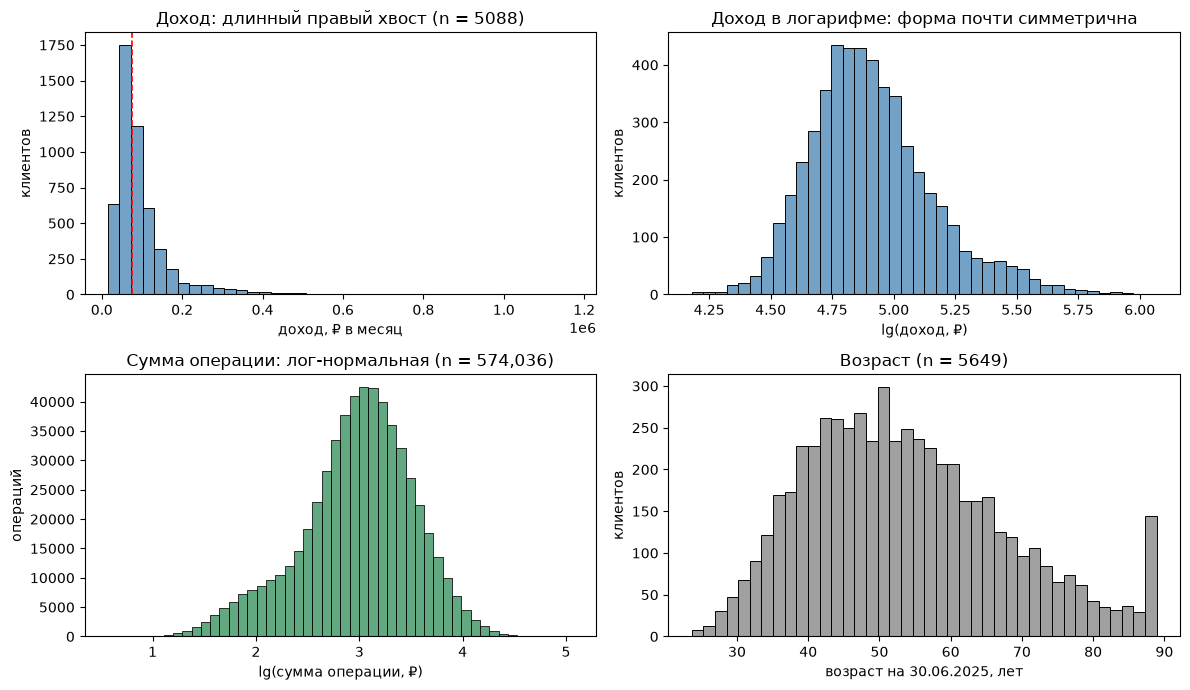

In [150]:
income = df_clients["monthly_income"].dropna()
age = (PERIOD_END - df_clients["birth_date"]).dt.days / 365.25

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

sns.histplot(income, bins=40, ax=axes[0, 0], color="steelblue")
axes[0, 0].axvline(income.median(), color="red", ls="--", lw=1.2)
axes[0, 0].set(xlabel="доход, ₽ в месяц", ylabel="клиентов", title=f"Доход: длинный правый хвост (n = {len(income)})")

sns.histplot(np.log10(income), bins=40, ax=axes[0, 1], color="steelblue")
axes[0, 1].set(xlabel="lg(доход, ₽)", ylabel="клиентов", title="Доход в логарифме: форма почти симметрична")

sns.histplot(np.log10(df_ops["amount_rub"]), bins=50, ax=axes[1, 0], color="seagreen")
axes[1, 0].set(xlabel="lg(сумма операции, ₽)", ylabel="операций", title=f"Сумма операции: лог-нормальная (n = {len(df_ops):,})")

sns.histplot(age, bins=40, ax=axes[1, 1], color="gray")
axes[1, 1].set(xlabel="возраст на 30.06.2025, лет", ylabel="клиентов", title=f"Возраст (n = {len(age)})")

plt.tight_layout()
plt.show()


#### Возраст: где именно начинается хвост

Посмотрим на правый хвост возраста отдельно: не «есть ли выбросы», а **на каком значении** плотность перестаёт вести себя как продолжение ряда. Это важно, потому что от ответа зависит, где проходит граница «пожилой клиент» и можно ли вообще считать возраст точным признаком на этом участке.


In [170]:
# --- где именно начинается хвост возраста
age = (PERIOD_END - df_clients["birth_date"]).dt.days / 365.25
birth = df_clients["birth_date"]

print("возраст на", PERIOD_END.date(), ":", round(age.min(), 1), "—", round(age.max(), 2))
print("даты рождения:", birth.min().date(), "—", birth.max().date())

tail = np.floor(age.loc[age.ge(80)]).astype(int).value_counts().sort_index()
lam = tail.loc[80:87].mean()
print("\nклиентов в каждом году возраста, 80+:")
print(tail.to_string())
print(f"\nсреднее за 80–87 лет: {lam:.1f} клиентов на год возраста")
print(f"на 88 лет: {tail.loc[88]} — в {tail.loc[88] / lam:.1f} раза больше")

per_month = birth.dt.to_period("M").value_counts().sort_index().loc["1936-07":"1938-06"]
print("\nклиентов по месяцу рождения, последние два года перед обрывом:")
print(per_month.to_string())
print(f"\nплотность до 1937-08: {per_month.loc['1936-08':'1937-07'].mean():.1f} клиентов в месяц; после 1937-08: {per_month.loc['1937-08':].mean():.1f}")

# --- кто эти люди: профиль группы 88+ против соседних
age_by_id = pd.Series(age.values, index=df_clients["client_id"].values)
txn_ok = df_transactions.loc[
    df_transactions["status"].eq("успешно") & df_transactions["client_id"].isin(df_clients["client_id"])
]
ops = txn_ok.groupby("client_id").size()

activity = df_clients[["client_id", "has_mobile_app", "monthly_income"]].assign(
    возраст=age.values,
    операций=lambda d: d["client_id"].map(ops).fillna(0),
    группа=lambda d: pd.cut(d["возраст"], [23, 70, 80, 85, 88, 89], right=False),
)
profile = activity.groupby("группа", observed=True).agg(
    клиентов=("client_id", "size"),
    с_операциями=("операций", lambda s: int(s.gt(0).sum())),
    медиана_операций=("операций", "median"),
    приложение=("has_mobile_app", lambda s: s.eq("Да").mean() * 100),
    доход=("monthly_income", lambda s: s.where(s.gt(0)).median()),
)
profile.columns = ["клиентов", "с операциями", "медиана операций", "приложение, %", "доход, медиана ₽"]
print("\nпрофиль по возрастным группам:")
print(profile.round(1).to_string())

old = age.ge(88)
print(f"\n88+: {int(old.sum())} клиентов, это {old.mean():.1%} базы")
print("пол:", df_clients.loc[old, "gender"].value_counts().to_dict())
print("приложение установлено:", int(df_clients.loc[old, "has_mobile_app"].eq("Да").sum()), "из", int(old.sum()))
print("возраст открытия карты, лет:",
      (df_clients.loc[old, "card_open_date"] - birth.loc[old]).dt.days.div(365.25)
      .describe()[["min", "50%", "max"]].round(1).to_dict())
print("клиентов без единой операции:", int(ops.reindex(df_clients.loc[old, "client_id"]).isna().sum()))
print("операций на клиента, медиана:", int(ops.reindex(df_clients.loc[old, "client_id"]).median()))


возраст на 2025-06-30 : 23.6 — 88.93
даты рождения: 1936-07-26 — 2001-11-09

клиентов в каждом году возраста, 80+:
birth_date
80     24
81     17
82     23
83     23
84     19
85     19
86     21
87     29
88    121

среднее за 80–87 лет: 21.9 клиентов на год возраста
на 88 лет: 121 — в 5.5 раза больше

клиентов по месяцу рождения, последние два года перед обрывом:
birth_date
1936-07     1
1936-08    14
1936-09     5
1936-10    17
1936-11     7
1936-12    12
1937-01    14
1937-02     6
1937-03    18
1937-04     6
1937-05     9
1937-06    12
1937-07    11
1937-08     4
1937-10     1
1937-11     1
1937-12     1
1938-01     3
1938-02     1
1938-03     3
1938-04     1
1938-05     2
1938-06     1
Freq: M

плотность до 1937-08: 10.9 клиентов в месяц; после 1937-08: 1.8

профиль по возрастным группам:
          клиентов  с операциями  медиана операций  приложение, %  доход, медиана ₽
группа                                                                             
[23, 70)      4883        

**Где начинается выброс: на 88.0 лет.** Не «примерно в старости», а на конкретном значении, и проверяется это тремя независимыми способами.

1. **Скачок плотности в годовом разрезе.** 80 лет — 24 клиента, 81 — 17, 82 — 23, 83 — 23, 84 — 19, 85 — 19, 86 — 21, 87 — 29, а 88 — **121**. Среднее за 80–87 равно 21.9, то есть последний год в 5.5 раза плотнее тренда; 
2. **Ступенька в месячном разрезе.** До августа 1937 года — 10.9 клиентов на месяц рождения, после — 1.8. Граница попадает ровно между июлем 1937 (11 клиентов) и августом 1937 (4), то есть на возраст 88.0.
3. **Жёсткий обрыв сверху.** Самый старый клиент — 88.93 года (родился 1936-07-26), и **старше нет ни одного человека**, хотя база — 5649 клиентов. Если бы хвост был естественным, за 121 клиентом на 88 годах стояли бы единицы на 89–95.

Отсюда механика: это не несколько невозможных возрастов (никаких 150 лет в данных нет), а **срез сверху с уплотнением последнего года**. Возраст выше границы не удалён, а сжат в последний год, поэтому «88» здесь читается как «88 и, возможно, больше». 

**Кто эти 121 человек.** Профиль правдоподобный, а не битые строки: пол 64 М / 57 Ж, приложение установлено у 27 из 121 (22.3% против 65.6% у клиентов до 70), медиана 58 операций против 91 у остальных, **ни одного клиента без операций**, карта открыта в возрасте 79.4–88.6 лет (медиана 83.5). Медиана дохода 92 600 ₽ — самая высокая по группам, но это связано с общим ростом дохода с возрастом в этих данных, а не с аномалией группы.

**Решение: не удалять, но перестать считать возраст числом на этом участке.** Удаление 121 клиента (2.1% базы) вырезало бы самую пожилую часть аудитории и ничего не исправило бы: истинный возраст этих людей неизвестен, он лишь «не меньше 88». Поэтому:

- возраст использовать категориями с открытым верхним интервалом (… 85–87, 88+), а не точками;
- не считать среднее, медиану и перцентили возраста по группе 88+ осмысленными;
- не строить правила кампании на пороге внутри последнего года («ровно 88 лет», «старше 88.5») — такой порог отделяет не людей, а артефакт сжатия;
- там, где числовой возраст всё же нужен, обрезать его сверху (`clip(upper=88)`) и оговаривать это в тексте.

Практический вывод для 5.1: остальные три признака (доход, сумма операции, число операций) описываются медианой и IQR спокойно, а по возрасту верхний хвост нужно держать в голове — именно из-за него «пожилая группа» в данных не является выборкой из реальных 88-летних.


**Меры центра и разброса — медиана и IQR, а не среднее и стандартное отклонение.** Доход и сумма операции распределены с длинным правым хвостом: у дохода среднее 98 953 ₽ против медианы 75 800 ₽ (выше на 31%), у суммы операции 1 866 ₽ против 1 066 ₽ (выше на 75%). В таких распределениях среднее сдвигается несколькими крупными значениями и перестаёт описывать типичного клиента, а стандартное отклонение — типичный разброс. Поэтому в таблице есть и медиана, и IQR, и квантили 5/95: они устойчивы к хвосту и не требуют ничего удалять.

Возраст — единственный признак без длинного правого хвоста: медиана 51.9 года, IQR 19.4, диапазон 23.6–88.9, среднее и медиана почти совпадают. Но дефект у него есть, только другого рода — срез сверху на 88 годах с уплотнением последнего года (разобран выше). Медиану и IQR он не портит, а вот точные значения возраста в группе 88+ использовать нельзя.

Число операций на клиента за 18 месяцев: медиана 88, IQR 85, максимум 608. Разрыв между медианой и максимумом почти семикратный, то есть «средний клиент» — плохое понятие, и любой показатель дальше надо считать в расчёте на клиента.


### 5.2. Частотные характеристики категориальных признаков

In [151]:
def frequency_table(series, name):
    table = series.value_counts(dropna=False).rename("значений").to_frame()
    table["доля, %"] = (table["значений"] / len(series) * 100).round(1)
    table.index.name = name
    return table


print("клиенты, знаменатель =", len(df_clients))
for column in ["segment", "loyalty_tier", "card_type", "city", "has_mobile_app", "marketing_opt_in", "income_source", "gender"]:
    print(f"\n{column}")
    print(frequency_table(df_clients[column], column).to_string())

print("\n\nоперации, знаменатель =", len(df_transactions))
for column in ["channel", "category", "status", "currency"]:
    print(f"\n{column}")
    print(frequency_table(df_transactions[column], column).to_string())


клиенты, знаменатель = 5649

segment
             значений  доля, %
segment                       
Массовый         2835     50.2
Зарплатный       1598     28.3
Премиальный       972     17.2
Private           244      4.3

loyalty_tier
              значений  доля, %
loyalty_tier                   
Базовый           2843     50.3
Серебро           1535     27.2
Золото             954     16.9
Платина            317      5.6

card_type
             значений  доля, %
card_type                     
Дебетовая        3905     69.1
Кредитная        1218     21.6
Премиальная       526      9.3

city
                 значений  доля, %
city                              
Москва               1651     29.2
Санкт-Петербург       998     17.7
Казань                907     16.1
Новосибирск           701     12.4
Нижний Новгород       697     12.3
Екатеринбург          695     12.3

has_mobile_app
                значений  доля, %
has_mobile_app                   
Да                  3460     61.2
Н

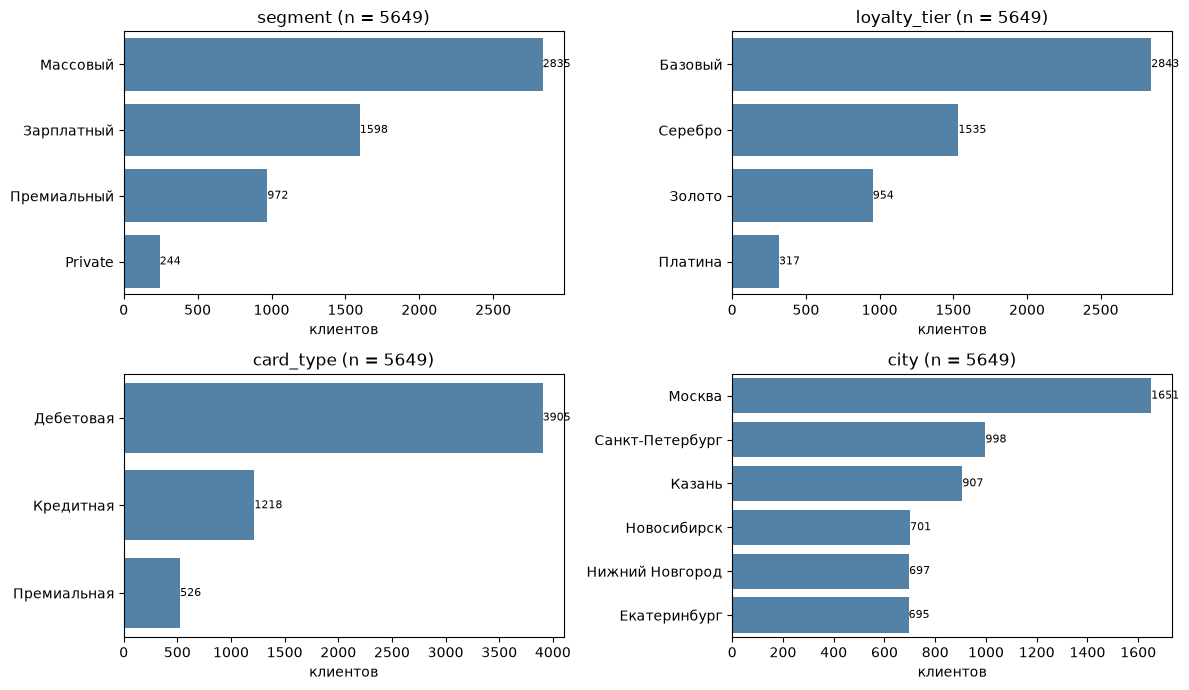

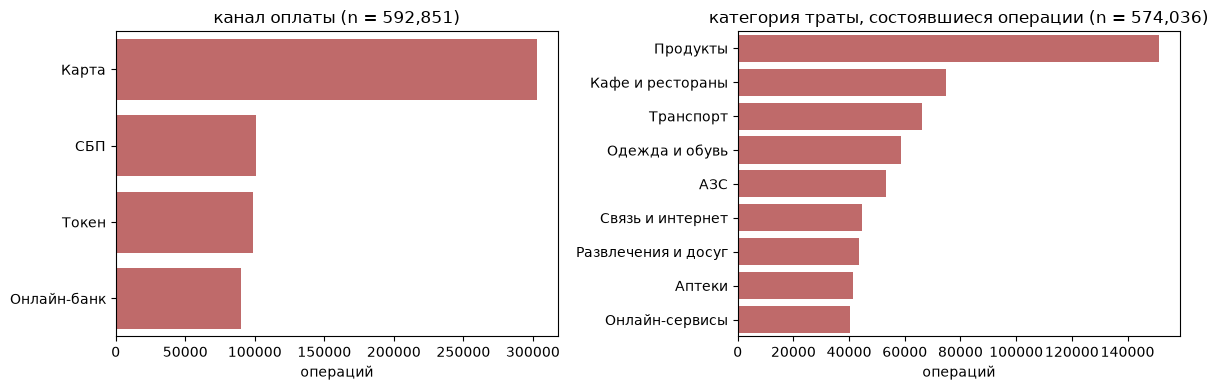

In [152]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, column in zip(axes.ravel(), ["segment", "loyalty_tier", "card_type", "city"]):
    order = df_clients[column].value_counts().index
    sns.countplot(data=df_clients, y=column, order=order, ax=ax, color="steelblue")
    ax.set(xlabel="клиентов", ylabel="", title=f"{column} (n = {len(df_clients)})")
    ax.bar_label(ax.containers[0], fontsize=8)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df_transactions, y="channel", order=df_transactions["channel"].value_counts().index, ax=axes[0], color="indianred")
axes[0].set(xlabel="операций", ylabel="", title=f"канал оплаты (n = {len(df_transactions):,})")

sns.countplot(data=df_ops, y="category", order=df_ops["category"].value_counts().index, ax=axes[1], color="indianred")
axes[1].set(xlabel="операций", ylabel="", title=f"категория траты, состоявшиеся операции (n = {len(df_ops):,})")

plt.tight_layout()
plt.show()


**Что видно в частотах.** База однородна по полу (50.7% женщин, 49.3% мужчин) и сильно неоднородна по сегменту: массовый — половина клиентов (50.2%), Private — 4.3%. Поэтому любое утверждение «в среднем по банку» фактически будет утверждением про массовый сегмент, и это надо помнить во всех разрезах.

Каналы: «Карта» 51.1%, остальные три делят вторую половину почти поровну — СБП 17.0%, Токен 16.7%, Онлайн-банк 15.2%. Категории: «Продукты» 26.3% — самая частая, далее «Кафе и рестораны» 13.0% и «Транспорт» 11.5%, редкая — «Онлайн-сервисы» 7.0%.

Статусы: 96.8% операций состоялись, 2.0% отклонены, 1.2% возвраты. Знаменатель здесь 592 851 — это операции, а не клиенты; доля отклонённых от числа клиентов не считается.

Согласие на коммуникацию дали 88.1% клиентов, то есть ограничение «только с согласием» отсекает около 12% базы независимо от сегмента.


### 5.3. Динамика по месяцам

In [153]:
month = df_ops["txn_datetime"].dt.to_period("M")

monthly = pd.DataFrame(
    {
        "операций": df_ops.groupby(month).size(),
        "клиентов": df_ops.groupby(month)["client_id"].nunique(),
        "медианный чек, ₽": df_ops.groupby(month)["amount_rub"].median().round(0),
        "доля не-«Карта», %": (df_ops.groupby(month)["channel"].apply(lambda s: s.ne("Карта").mean() * 100)).round(1),
    }
)
monthly.index = monthly.index.astype(str)
monthly.index.name = "месяц"
monthly


,операций,клиентов,"медианный чек, ₽","доля не-«Карта», %"
месяц,,,,
2024-01,23969,4643,1073.0,46.9
2024-02,30288,4734,1073.0,47.2
2024-03,34863,4768,1073.0,47.1
2024-04,33728,4754,1069.0,46.7
2024-05,31184,4762,1091.0,46.9
2024-06,33599,4763,1088.0,46.8
2024-07,34374,4784,1078.0,47.3
2024-08,35700,4857,1071.0,46.7
2024-09,33973,4914,1076.0,47.0


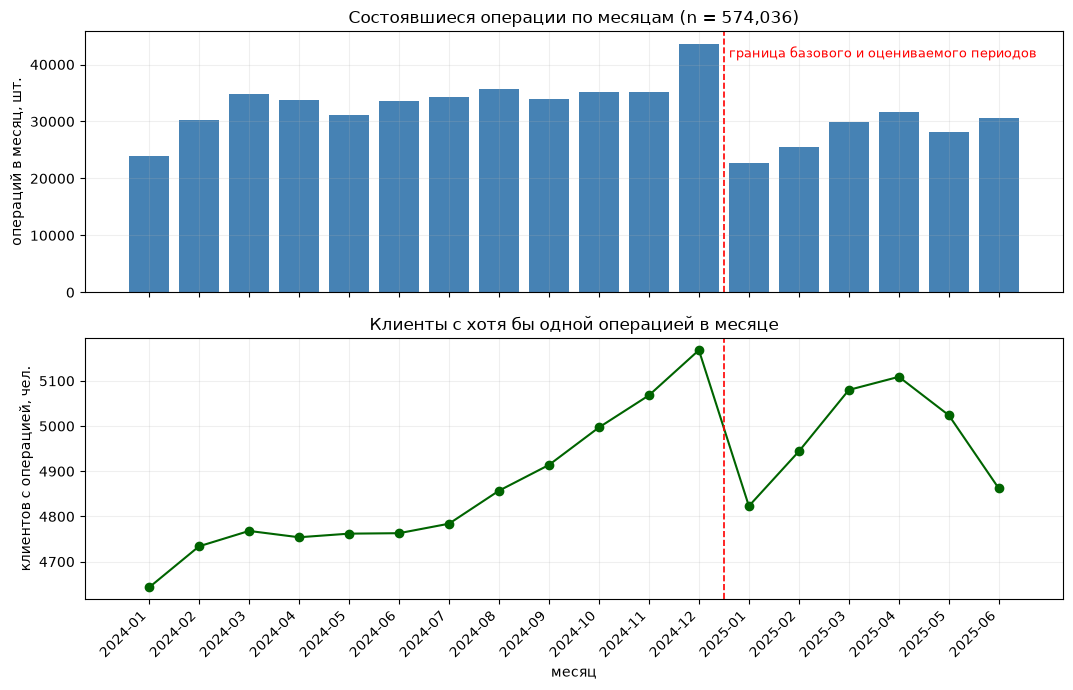

In [154]:
x = np.arange(len(monthly))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].bar(x, monthly["операций"], color="steelblue")
axes[0].set(ylabel="операций в месяц, шт.", title=f"Состоявшиеся операции по месяцам (n = {len(df_ops):,})")

axes[1].plot(x, monthly["клиентов"], marker="o", color="darkgreen")
axes[1].set(ylabel="клиентов с операцией, чел.", xlabel="месяц", title="Клиенты с хотя бы одной операцией в месяце")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(monthly.index, rotation=45, ha="right")
    ax.axvline(11.5, color="red", ls="--", lw=1.2)
    ax.grid(alpha=0.2)

axes[0].annotate("граница базового и оцениваемого периодов", xy=(11.6, axes[0].get_ylim()[1] * 0.9), fontsize=9, color="red")

plt.tight_layout()
plt.show()


**Динамика по месяцам.** Ряд читается только вместе с календарём: максимум — декабрь 2024 (43 646 операций), минимум — январь 2025 (22 648). Январь 2024 тоже низкий (23 969), декабрь высокий, и в январе 2024 суточные пики приходятся на 5–6 и 20–21 числа, то есть на выходные. Это сезонность и календарь, а не падение активности; к тому же месяцы различаются числом выходных дней.

Три вещи, которые видны уже на этом уровне и от сезонности не зависят:

1. Число клиентов с хотя бы одной операцией за месяц не падает: 4643 в январе 2024 → 5168 в декабре 2024 → 4862 в июне 2025. Охват держится, меняется интенсивность, а не число людей.
2. Медианный чек снизился: 1069–1092 ₽ в 2024 против 1031–1047 ₽ в 2025 — примерно на 3–5%.
3. Доля не-«Карта» выросла с 46.7–47.6% в 2024 до 50.7–55.3% в 2025: клиенты чаще платят телефоном и через СБП, реже пластиком.

Ограничение, которое из этого следует: окна разной длины (12 и 6 месяцев) и разная сезонность внутри них, поэтому сравнивать суммы «2024 против 2025» напрямую нельзя — только в расчёте на месяц и с поправкой на календарь.


### 5.4. Разрезы и связи между признаками

In [155]:
print("доля клиентов с приложением внутри сегмента, %")
print(pd.crosstab(df_clients["segment"], df_clients["has_mobile_app"], normalize="index").mul(100).round(1).to_string())

print("\nдоход по сегментам, ₽")
print(
    df_clients.groupby("segment", observed=True)["monthly_income"]
    .agg(n="count", медиана="median", Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75))
    .round(0)
    .to_string()
)

print("\nтип карты внутри сегмента, %")
print(pd.crosstab(df_clients["segment"], df_clients["card_type"], normalize="index").mul(100).round(1).to_string())

print("\nканал внутри категории траты, %")
print(pd.crosstab(df_ops["category"], df_ops["channel"], normalize="index").mul(100).round(1).to_string())

print("\nдоля согласившихся на коммуникацию внутри сегмента, %")
print((df_clients.groupby("segment", observed=True)["marketing_opt_in"].apply(lambda s: s.eq("Да").mean() * 100)).round(1).to_string())


доля клиентов с приложением внутри сегмента, %
has_mobile_app    Да   Нет
segment                   
Private         56.1  43.9
Зарплатный      62.2  37.8
Массовый        62.0  38.0
Премиальный     58.7  41.3

доход по сегментам, ₽
                n   медиана        Q1        Q3
segment                                        
Private       215  327600.0  257250.0  418000.0
Зарплатный   1518   78000.0   60425.0  101475.0
Массовый     2466   60000.0   46125.0   77900.0
Премиальный   889  145600.0  110700.0  183200.0

тип карты внутри сегмента, %
card_type    Дебетовая  Кредитная  Премиальная
segment                                       
Private           20.1       13.5         66.4
Зарплатный        72.0       25.5          2.5
Массовый          80.6       18.5          1.0
Премиальный       43.4       26.0         30.6

канал внутри категории траты, %
channel              Карта  Онлайн-банк   СБП  Токен
category                                            
АЗС                   50.9   

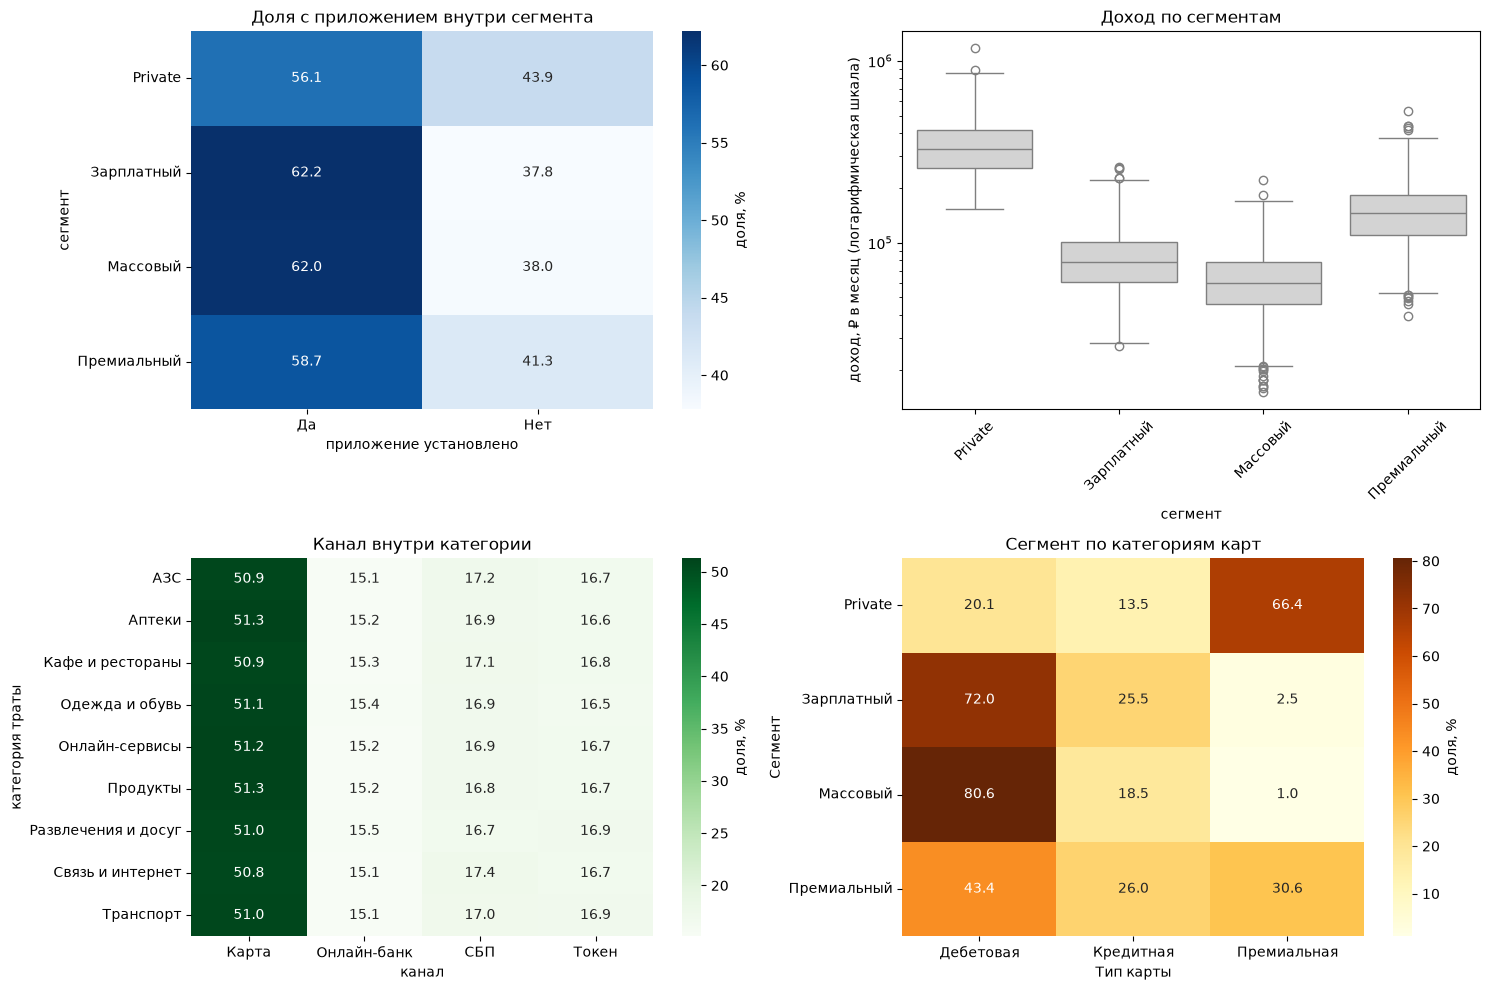

In [165]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

share_app = pd.crosstab(df_clients["segment"], df_clients["has_mobile_app"], normalize="index").mul(100)
sns.heatmap(share_app, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "доля, %"}, ax=axes[0, 0])
axes[0, 0].set(xlabel="приложение установлено", ylabel="сегмент", title="Доля с приложением внутри сегмента")

sns.boxplot(data=df_clients, x="segment", y="monthly_income", ax=axes[0, 1], log_scale=True, color="lightgray")
axes[0, 1].set(xlabel="сегмент", ylabel="доход, ₽ в месяц (логарифмическая шкала)", title="Доход по сегментам")
axes[0, 1].tick_params(axis="x", rotation=45)

channel_share = pd.crosstab(df_ops["category"], df_ops["channel"], normalize="index").mul(100)
sns.heatmap(channel_share, annot=True, fmt=".1f", cmap="Greens", cbar_kws={"label": "доля, %"}, ax=axes[1, 0])
axes[1, 0].set(xlabel="канал", ylabel="категория траты", title="Канал внутри категории")

card_in_segment = pd.crosstab(df_clients["segment"], df_clients["card_type"], normalize="index").mul(100).round(1)
sns.heatmap(card_in_segment, annot=True, fmt=".1f", cmap="YlOrBr", cbar_kws={"label": "доля, %"}, ax=axes[1, 1])
axes[1, 1].set(xlabel="Тип карты", ylabel="Сегмент", title="Сегмент по категориям карт")

plt.tight_layout()
plt.show()


**Разрезы.** Сегмент — самый информативный признак, и он связан почти со всем:

- доход: медиана 60 000 ₽ у массового, 78 000 у зарплатного, 145 600 у премиального, 327 600 у Private. Разрыв в 5.5 раза, причём у крайних сегментов не перекрываются даже IQR;
- тип карты: у массового и зарплатного это «Дебетовая» (80.6% и 72.0%), у Private — «Премиальная» (66.4%);
- приложение: доля владельцев почти одинакова — 56.1% у Private против 62.2% у зарплатного, то есть наличие приложения сегменты не различает;
- согласие на коммуникацию: 87.2–88.4% во всех сегментах, тоже не различает.

Пара, где связи нет вовсе, — канал и категория траты: во всех девяти категориях распределение каналов одинаково (≈51% Карта, 17% СБП, 17% Токен, 15% Онлайн-банк). Канал описывает способ оплаты, а не тип покупки, и как признак «кто это» он дублирует сам себя.

Вывод для дальнейшего: сегмент, уровень лояльности, тип карты и доход — связанные признаки, их нельзя предъявлять заказчику как независимые причины. Наличие приложения и согласие на коммуникацию от сегмента не зависят, поэтому годятся и как признак группы, и как ограничение кампании.


## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [ ]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")